# Figure 5a. SEC61G locus: *cis*-eQTL and microglia *trans*-QTL

Marginal association -log10(p) on chromosome 7 (variants 6,000-12,000 of the 51.4-61.0 Mb TransMap colocalization region, about 53.4-56.2 Mb) for the excitatory neuron *SEC61G* *cis*-eQTL, four microglia *trans*-eGene QTL (*ZFP36*, *EPHB2*, *PTAFR*, *MAP4K4*) and two microglia *trans*-eProgram QTL (Programs 31 and 100). P-values are two-sided, computed from the marginal z-scores stored in the ColocBoost object (p = 2Φ(-|z|), as in `colocboost_plot()`). Blue points are the 38 variants of the single robust colocalization confidence set (95% CoS; `get_robust_colocalization()` with p < 1e-5, cos_npc ≥ 0.5, npc_outcome > 0.2), which includes all seven traits. The gene track shows Ensembl GRCh38.103 protein-coding genes in the window.

Input: `data/Figure_5a_sec61g_locus.rds` (list with `locus` and `genes`).

In [1]:
library(ggplot2)
library(patchwork)
library(ggrepel)
fig5a <- readRDS("data/Figure_5a_sec61g_locus.rds")
locus <- fig5a$locus
genes <- fig5a$genes
head(locus)
table(locus$trait, locus$colocalized)
genes

,trait,variant,position_bp,z,neglog10_p,colocalized
,<fct>,<chr>,<dbl>,<dbl>,<dbl>,<lgl>
1,Excitatory neuron SEC61G cis-eQTL,chr7:53391013:T:C,53391013,0.8254829,0.3881732,FALSE
2,Excitatory neuron SEC61G cis-eQTL,chr7:53391058:T:C,53391058,-1.9120293,1.2528024,FALSE
3,Excitatory neuron SEC61G cis-eQTL,chr7:53392225:T:A,53392225,0.9574334,0.4706357,FALSE
4,Excitatory neuron SEC61G cis-eQTL,chr7:53392377:T:C,53392377,1.0037588,0.5010077,FALSE
5,Excitatory neuron SEC61G cis-eQTL,chr7:53392638:AT:A,53392638,1.8997768,1.2406161,FALSE
6,Excitatory neuron SEC61G cis-eQTL,chr7:53392926:T:TA,53392926,-1.8044857,1.1477933,FALSE


                                            
                                             FALSE TRUE
  Excitatory neuron SEC61G cis-eQTL           5963   38
  Microglia ZFP36 trans-eGene QTL             5963   38
  Microglia EPHB2 trans-eGene QTL             5963   38
  Microglia PTAFR trans-eGene QTL             5963   38
  Microglia MAP4K4 trans-eGene QTL            5963   38
  Microglia trans-eProgram QTL (Program 31)   5963   38
  Microglia trans-eProgram QTL (Program 100)  5963   38

gene,start_bp,end_bp,strand,is_cis_gene
<chr>,<int>,<int>,<chr>,<lgl>
VSTM2A,54542325,54571080,+,FALSE
SEC61G,54752250,54759974,-,TRUE
EGFR,55019017,55211628,+,FALSE
LANCL2,55365337,55433737,+,FALSE
VOPP1,55436056,55572988,-,FALSE
SEPTIN14,55793540,55862755,-,FALSE
ZNF713,55887456,55942530,+,FALSE
NIPSNAP2,55951793,56000181,+,FALSE
MRPS17,55951877,55956500,+,FALSE


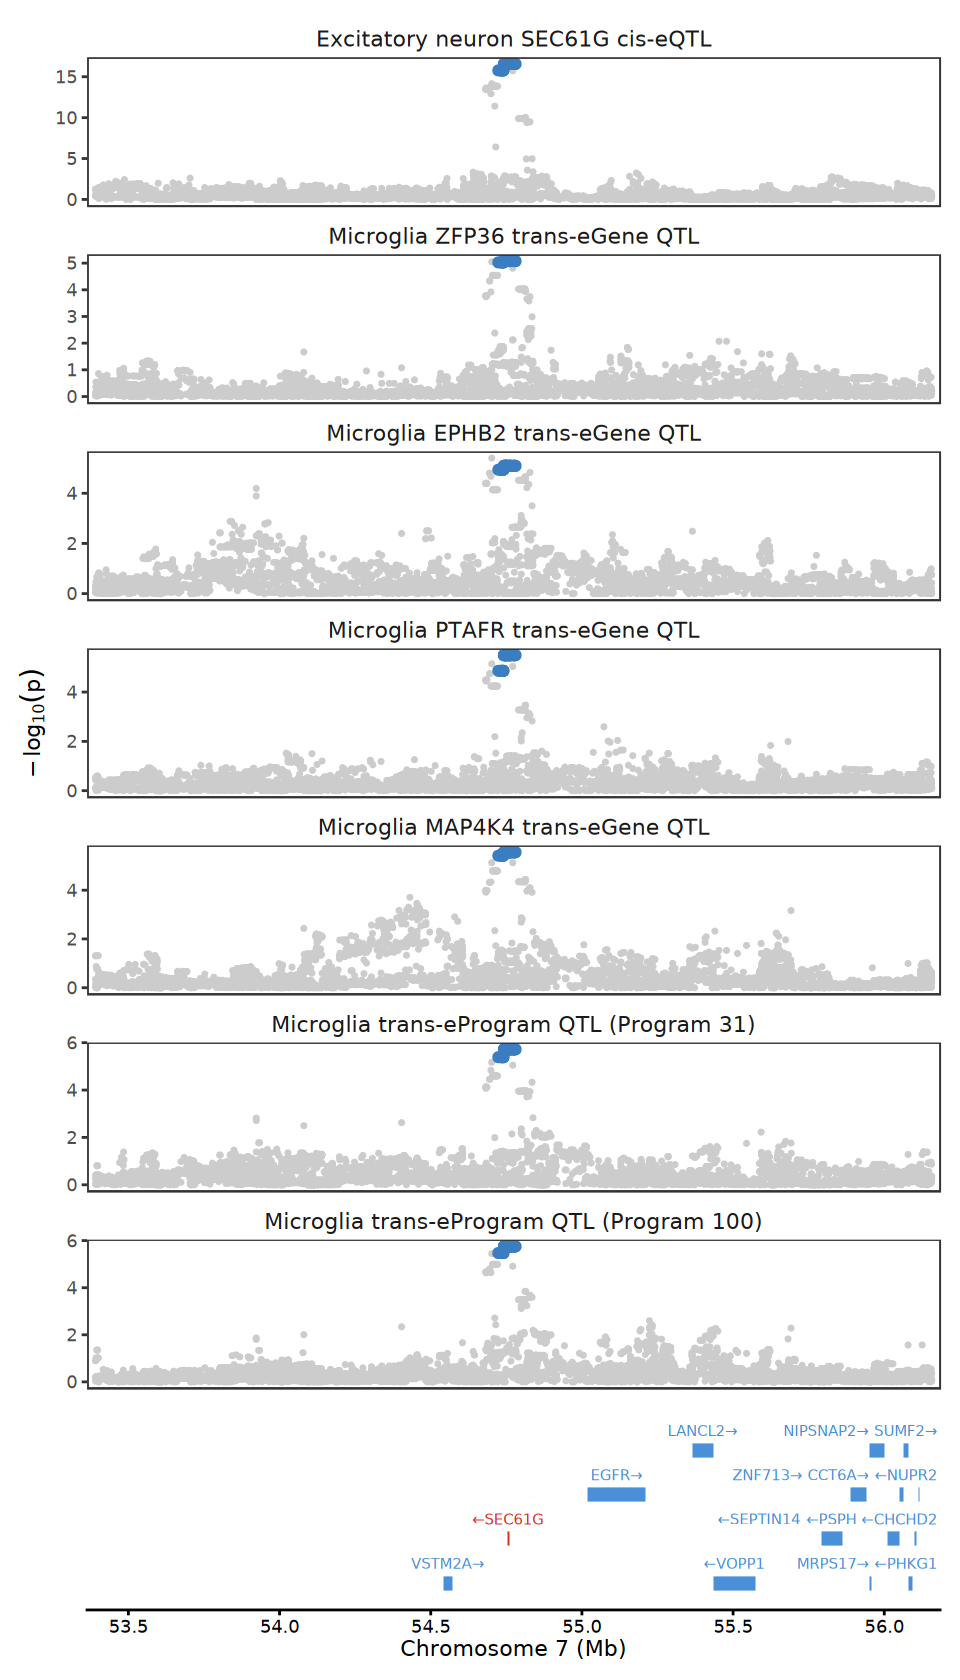

In [2]:
x_lim <- range(locus$position_bp) / 1e6

p_locus <- ggplot(locus, aes(x = position_bp / 1e6, y = neglog10_p)) +
  geom_point(data = subset(locus, !colocalized), colour = "grey80", size = 0.8) +
  geom_point(data = subset(locus, colocalized), colour = "#3A7DC0", size = 2.2) +
  facet_wrap(~ trait, ncol = 1, scales = "free_y") +
  scale_x_continuous(limits = x_lim, expand = expansion(mult = 0.01)) +
  labs(x = NULL, y = expression(-log[10](p))) +
  theme_bw(base_size = 13) +
  theme(panel.grid = element_blank(),
        strip.background = element_blank(),
        strip.text = element_text(size = 13),
        axis.text.x = element_blank(), axis.ticks.x = element_blank())

genes$start_bp <- pmax(genes$start_bp, min(locus$position_bp))  # clip to plotted window
genes$end_bp <- pmin(genes$end_bp, max(locus$position_bp))
genes$row <- rep_len(1:4, nrow(genes))
genes$label <- ifelse(genes$strand == "+", paste0(genes$gene, "\u2192"), paste0("\u2190", genes$gene))
p_genes <- ggplot(genes) +
  geom_segment(aes(x = start_bp / 1e6, xend = end_bp / 1e6, y = row, yend = row,
                   colour = is_cis_gene), linewidth = 3) +
  geom_text_repel(aes(x = (start_bp + end_bp) / 2e6, y = row, label = label,
                      colour = is_cis_gene), size = 3, nudge_y = 0.45, direction = "x",
                      min.segment.length = Inf, box.padding = 0.1, seed = 1) +
  scale_colour_manual(values = c(`FALSE` = "#4A90D9", `TRUE` = "#D7301F"), guide = "none") +
  scale_x_continuous(limits = x_lim, expand = expansion(mult = 0.01)) +
  scale_y_continuous(limits = c(0.6, 4.7)) +
  labs(x = "Chromosome 7 (Mb)", y = NULL) +
  theme_classic(base_size = 13) +
  theme(axis.line.y = element_blank(), axis.text.y = element_blank(), axis.ticks.y = element_blank())

options(repr.plot.width = 8, repr.plot.height = 14)
p_locus / p_genes + plot_layout(heights = c(12, 1.8))